# Q2 — A domain-specific embedder for securities-law filings

**Question.** Does an embedder adapted to these five filings separate their subject matter better than a
general-purpose baseline, and how does it compare with a classical domain model?

| Model | What it is | Dim |
|---|---|---|
| `baseline` | `sentence-transformers/all-MiniLM-L6-v2`, as published | 384 |
| `lsa` | TF-IDF + truncated SVD fit on the training split (classical domain model) | 128 |
| `domain` | MiniLM fine-tuned self-supervised on the training split, plus a linear head to 128-d | 128 |

The stages live in `src/virallens/embedder/` — `data.py` (preprocessing), `train.py` (training),
`embed.py` (embedding), `cluster.py` (clustering and metrics), `plots.py` — and this notebook calls
them in order. `python -m virallens.embedder` runs the same study headless. Embeddings are kept
short (128-d), as the brief allows.

In [1]:
import collections
import os
import random
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # paths resolve against the repository root
os.environ["TQDM_DISABLE"] = "1"

from IPython.display import Image, Markdown, display

from virallens.common.corpus import load_corpus
from virallens.common.settings import Paths
from virallens.embedder.data import ict_pairs, labels, section_neighbour_pairs, split_by_page_blocks
from virallens.embedder.study import SEEDS, run_study, write_outputs

paths = Paths()
OUT = Path("research/outputs")

## 1. Preprocessing

The filings go through the same cleaner and structure-aware chunker as Q1 (`virallens.common`):
page furniture removed, hyphenation repaired, split at headings, chunks of at most 1000 characters.

**Held-out split.** Pages are dealt to train and test in contiguous 3-page blocks, one block in four
held out, so every filing — even the 11-page Macquarie opinion — has test pages. A test chunk that
shares any 100-character verbatim span with a training chunk is **dropped**: this catches chunk
overlap, a counsel block the complaint repeats on pp. 48 and 51, Macquarie's syllabus restating its
opinion, and recurring boilerplate. Topic, document-type and filing labels come from the catalogue
and are used **only to score**.

In [2]:
chunks = load_corpus(paths.data_dir)
split = split_by_page_blocks(chunks)
dropped = len(chunks) - len(split.train) - len(split.test)
print(
    f"{len(chunks)} chunks -> train {len(split.train)}, test {len(split.test)}, dropped {dropped}"
)
for kind in ("topic", "doc"):
    print(f"test by {kind}:", dict(collections.Counter(labels(split.test, kind))))

370 chunks -> train 279, test 72, dropped 19
test by topic: {'disclosure_omissions': 50, 'specialist_execution': 10, 'fund_concentration': 12}
test by doc: {'fb-petitioners': 27, 'macquarie': 2, 'fb-united-states': 21, 'last-atlantis': 10, 'sec-v-chiueh': 12}


## 2. Self-supervised training pairs

Training uses no labels. Two kinds of positive pair come from the training split:

- **Inverse Cloze Task** (Lee et al., 2019): one sentence is the query for the rest of its passage,
  with the sentence removed; a new sentence is sampled each epoch.
- **Section neighbours**: two chunks of the same section, two apart in the filing, so they share an
  argument but no overlap text. These pairs follow document structure, so filing identity (and with
  it topic) shapes which pairs are positive — a limitation discussed below.

MultipleNegativesRankingLoss (the other pairs in a batch are negatives), 4 epochs, batch 16, on CPU
so each seed is reproducible.

In [3]:
sentence, passage = ict_pairs(split.train, random.Random(0))[5]
first, second = section_neighbour_pairs(split.train)[5]
print("ICT query   :", sentence[:160])
print("ICT passage :", passage[:160], "...")
print()
print("neighbour A :", first[:160])
print("neighbour B :", second[:160])
n_ict = len(ict_pairs(split.train, random.Random(0)))
n_neighbour = len(section_neighbour_pairs(split.train))
print(f"\n{n_ict} ICT + {n_neighbour} neighbour pairs per epoch")

ICT query   : The question presented is whether that theory of securities fraud is valid under Section 10(b) and Rule 10b-5(b).
ICT passage : Despite the obviously forward-looking and probabilistic nature of such risk disclosures, private plaintiffs have increasingly brought securities actions allegin ...

neighbour A : 3. On March 20, 2018, two days after the news reports concerning Cambridge Analytica, a class-action complaint was filed against Meta and others in the United S
neighbour B : Security breaches and improper access to or disclosure of our data or user data, or other hacking and phishing attacks on our systems, could harm our reputation

265 ICT + 156 neighbour pairs per epoch


## 3. Train, embed and cluster — 3 seeds

For each seed: fit LSA, fine-tune the domain model (about 2 minutes on CPU), embed the held-out
chunks with all three models, cluster them with KMeans and score. Outputs go to `research/outputs/`.

In [4]:
results = run_study(paths, SEEDS)
write_outputs(results, OUT)

## 4. Metrics

All on held-out chunks with cosine geometry, mean ± std over seeds 0, 1 and 2:

1. **Silhouette** of the reference labelling (−1 to 1): are same-label chunks closer than others?
2. **ARI / NMI** of KMeans (k = number of labels) against the labelling.
3. **kNN purity**: share of each chunk's 5 nearest neighbours with its label (read for topic labels).
4. **Similarity gap**: mean cosine within a label minus mean cosine across labels.
5. **Retrieval MRR**: the Q1 evaluation questions whose answering passage is held out, ranked against
   the held-out passages only, so no model is rewarded for remembering training text.
6. **Neighbour checks** and **KMeans cluster composition** (qualitative).

In [5]:
display(Markdown((OUT / "summary.md").read_text()))

Held-out chunks: 72 (train: 279)

### Labels: topic

| metric | baseline | lsa | domain |
|---|---|---|---|
| silhouette | 0.191 ± 0.000 | 0.256 ± 0.001 | 0.307 ± 0.007 |
| ari | 0.307 ± 0.012 | 0.769 ± 0.327 | 0.462 ± 0.138 |
| nmi | 0.523 ± 0.039 | 0.857 ± 0.202 | 0.615 ± 0.076 |
| knn_purity | 0.956 ± 0.000 | 0.982 ± 0.001 | 0.962 ± 0.007 |
| similarity_gap | 0.144 ± 0.000 | 0.206 ± 0.001 | 0.226 ± 0.002 |

### Labels: doc_type

| metric | baseline | lsa | domain |
|---|---|---|---|
| silhouette | 0.189 ± 0.000 | 0.247 ± 0.001 | 0.308 ± 0.011 |
| ari | 0.292 ± 0.011 | 0.708 ± 0.284 | 0.468 ± 0.174 |
| nmi | 0.522 ± 0.039 | 0.784 ± 0.146 | 0.612 ± 0.101 |
| knn_purity | 0.939 ± 0.000 | 0.967 ± 0.000 | 0.951 ± 0.003 |
| similarity_gap | 0.149 ± 0.000 | 0.211 ± 0.001 | 0.230 ± 0.001 |

### Labels: doc

| metric | baseline | lsa | domain |
|---|---|---|---|
| silhouette | 0.114 ± 0.000 | 0.208 ± 0.001 | 0.196 ± 0.010 |
| ari | 0.346 ± 0.030 | 0.507 ± 0.011 | 0.433 ± 0.007 |
| nmi | 0.556 ± 0.033 | 0.677 ± 0.007 | 0.614 ± 0.008 |
| knn_purity | 0.728 ± 0.000 | 0.820 ± 0.001 | 0.781 ± 0.016 |
| similarity_gap | 0.134 ± 0.000 | 0.224 ± 0.001 | 0.201 ± 0.001 |

### Retrieval MRR: 6 eval questions answered by a held-out passage, ranked against the 72 held-out passages

| baseline | lsa | domain |
|---|---|---|
| 0.774 ± 0.000 | 0.853 ± 0.001 | 0.695 ± 0.035 |

Questions: macquarie-holding, kogan-quiz, overdisclosure, concentration-policy, fb-positions-compared, macquarie-in-facebook

### Domain model training loss (mean per epoch)

- seed 0: 1.900, 1.212, 0.951, 0.863
- seed 1: 1.871, 1.204, 0.955, 0.866
- seed 2: 1.883, 1.185, 0.908, 0.895

### KMeans (k = 3) cluster composition by topic (seed 0)

- baseline: cluster 0: disclosure_omissions 33, specialist_execution 9; cluster 1: disclosure_omissions 16; cluster 2: disclosure_omissions 1, fund_concentration 12, specialist_execution 1
- lsa: cluster 0: disclosure_omissions 50; cluster 1: fund_concentration 12; cluster 2: specialist_execution 10
- domain: cluster 0: disclosure_omissions 31, specialist_execution 1; cluster 1: fund_concentration 12, specialist_execution 9; cluster 2: disclosure_omissions 19

### Nearest held-out neighbours (seed 0)

**macquarie p. 11**: * * * Pure omissions are not actionable under Rule 10b-5(b). The judgment of the Court of …
- baseline (1/3 same filing): macquarie p. 11 (0.678), fb-petitioners p. 23 (0.573), fb-petitioners p. 36 (0.518)
- lsa (1/3 same filing): macquarie p. 11 (0.545), fb-petitioners p. 23 (0.337), last-atlantis p. 10 (0.314)
- domain (1/3 same filing): macquarie p. 11 (0.796), fb-united-states p. 10 (0.661), last-atlantis p. 11 (0.653)

**fb-petitioners p. 10**: Petitioners are Facebook, Inc., now known as Meta Platforms, Inc., which operates the soci…
- baseline (2/3 same filing): fb-petitioners p. 48 (0.799), fb-petitioners p. 35 (0.784), fb-united-states p. 11 (0.779)
- lsa (2/3 same filing): fb-petitioners p. 35 (0.847), fb-petitioners p. 48 (0.721), fb-united-states p. 11 (0.717)
- domain (2/3 same filing): fb-petitioners p. 35 (0.849), fb-united-states p. 11 (0.844), fb-petitioners p. 10 (0.838)

**fb-united-states p. 10**: 229.105(a). That discussion “must be organized logically with relevant headings” and with …
- baseline (1/3 same filing): fb-petitioners p. 11 (0.58), fb-united-states p. 34 (0.575), fb-petitioners pp. 23-24 (0.572)
- lsa (2/3 same filing): fb-united-states p. 36 (0.351), fb-petitioners pp. 23-24 (0.256), fb-united-states pp. 36-37 (0.243)
- domain (2/3 same filing): fb-united-states p. 34 (0.663), fb-petitioners p. 23 (0.629), fb-united-states p. 35 (0.621)

**last-atlantis p. 10**: With no Seventh Circuit case law directly on point , I will3 follow the Second Circuit’s h…
- baseline (3/3 same filing): last-atlantis p. 10 (0.801), last-atlantis p. 11 (0.733), last-atlantis p. 10 (0.661)
- lsa (3/3 same filing): last-atlantis p. 10 (0.747), last-atlantis p. 11 (0.717), last-atlantis p. 11 (0.705)
- domain (3/3 same filing): last-atlantis p. 10 (0.884), last-atlantis p. 11 (0.863), last-atlantis pp. 12-13 (0.838)

**sec-v-chiueh p. 10**: 28. A mutual fund’s portfolio is managed by a Commission-registered investment adviser. A …
- baseline (3/3 same filing): sec-v-chiueh pp. 10-11 (0.76), sec-v-chiueh pp. 11-12 (0.571), sec-v-chiueh p. 22 (0.47)
- lsa (3/3 same filing): sec-v-chiueh pp. 10-11 (0.641), sec-v-chiueh pp. 34-35 (0.462), sec-v-chiueh pp. 11-12 (0.44)
- domain (3/3 same filing): sec-v-chiueh pp. 10-11 (0.8), sec-v-chiueh pp. 34-35 (0.641), sec-v-chiueh pp. 11-12 (0.616)


## 5. Visualisations

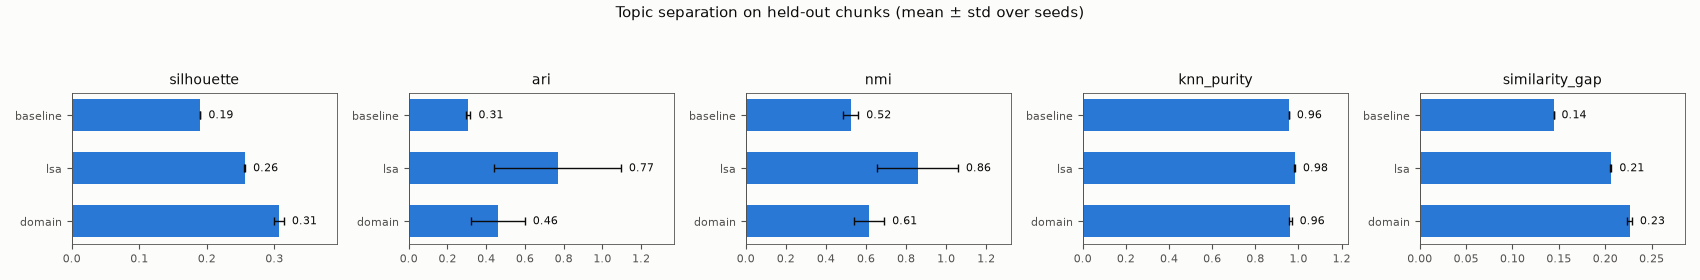

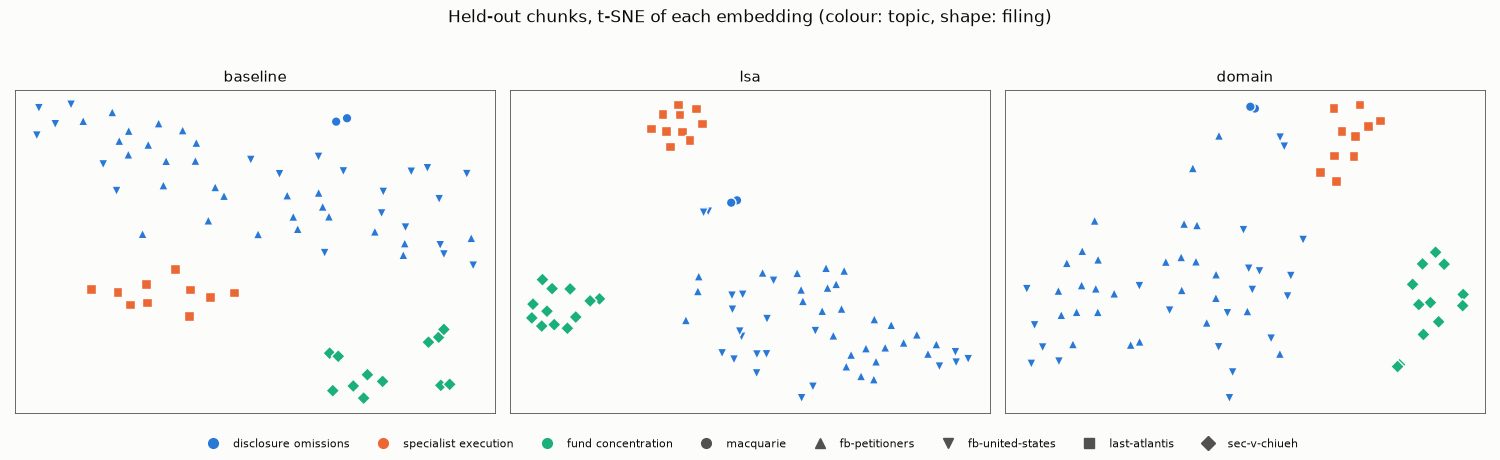

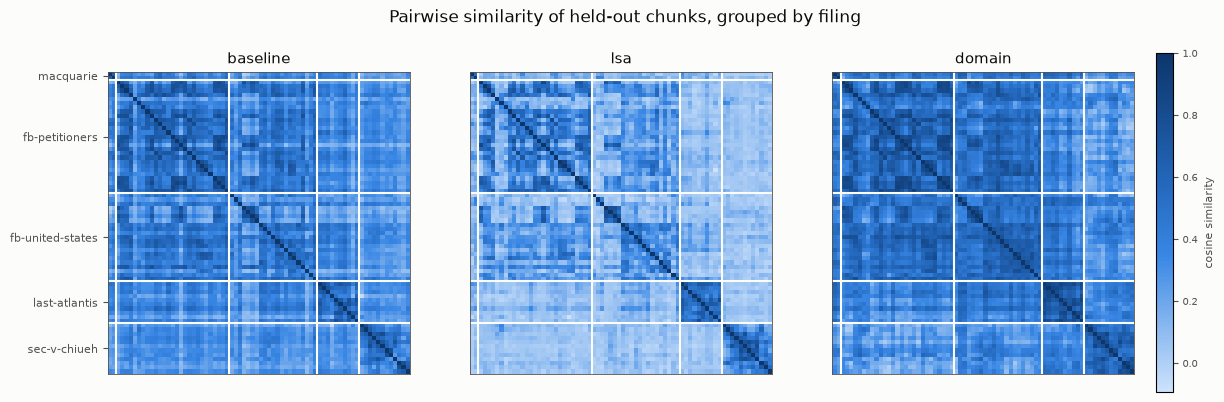

In [6]:
display(Image(OUT / "metrics_topic.png"))
display(Image(OUT / "tsne.png"))
display(Image(OUT / "similarity.png"))

## 6. Findings, model behaviour and challenges

### Findings

1. **Fine-tuning improves how well the encoder separates topics.** Silhouette rises from 0.191 to
   0.307 (± 0.007 over seeds), the similarity gap from 0.144 to 0.226 and KMeans ARI from 0.307 to
   0.462. Topic kNN purity barely moves (0.956 to 0.962, within seed noise).
2. **The classical domain model is the stronger one overall.** LSA fit on the same 279 training
   chunks has the best ARI (0.769), NMI (0.857), kNN purity (0.982), every filing-level metric and
   held-out retrieval (MRR 0.853). The fine-tuned model leads only on silhouette and similarity gap.
   What separates these filings is largely vocabulary — *Concentration Policy*, *specialist*,
   *Item 105* — which TF-IDF captures directly.
3. **Fine-tuning made question-to-passage retrieval worse.** On the six questions whose answers are
   held out, MRR falls from 0.774 (baseline) to 0.695 ± 0.035. The training task, a sentence finding
   its own passage, is not the task of a question finding the passage that answers it, and the
   128-d head discards some of the baseline's capacity. Six questions is a small sample.
4. **ARI and NMI partly measure KMeans.** With topics of 50, 10 and 12 held-out chunks, KMeans favours
   similar-sized clusters: on seed 0 it splits the large disclosure topic for the baseline (33/16)
   and the domain model (31/19) and folds the specialist chunks into another cluster, while LSA
   recovers all three topics. Silhouette and kNN purity, which do not depend on KMeans, are the
   steadier comparison.

### Model behaviour

- **The domain model raises cosine similarity everywhere** (darker heatmap; nearest neighbours at
  0.62–0.88), so absolute cosines are not comparable across models — only the gap is. A Macquarie
  chunk's second and third neighbours come from other filings at 0.66 and 0.65.
- **No model separates the two opposing Facebook briefs**: each brief's nearest neighbours include
  the other's. The embeddings capture subject matter, not stance — both briefs argue over the same
  facts and rules.
- Training loss is still falling after 4 epochs (seed 0: 1.900 → 1.212 → 0.951 → 0.863); the epoch
  count is untuned.

### Challenges

- **Very little data**: 5 filings, 370 chunks, 72 held out; Macquarie keeps only 2 held-out chunks,
  so its filing-level scores are thin.
- **Leakage is easy to miss**: chunk overlap, a repeated counsel block, a syllabus that restates its
  opinion and recurring boilerplate all put test text into training until the 100-character span
  filter removed 19 chunks; a brute-force test keeps the split leak-free.
- **No labels for training**, by design — but section-neighbour pairs encode document structure, so
  they teach each filing's style as well as its subject, and the filing-level gains partly reflect it.
- Hyperparameters are untuned (epochs, learning rates), and the comparison is on a single corpus.

### What I would try next

Hard negatives drawn from the other filings; domain-adaptive pre-training (e.g. TSDAE) on a larger
set of SEC filings before contrastive tuning; a fusion of LSA and the domain model (as Q1 fuses BM25
and dense retrieval); density-based clustering (HDBSCAN) that does not assume equal cluster sizes.